In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "utils"))

from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import cathodeparams, anodeparams, membraneparams, cellparams

## -- Parameters --

In [2]:
# -- Tests to include ----------------------------------------------------------
TEST_NOS = [5, 16, 25]

# -- Solver settings -------------------------------------------------------
TF     = 1800
RTOL   = 1e-5
STRIDE = 1

## -- Load experimental data and per-test fits --

In [3]:
# -- Per-test HFR membrane fit + E-cell kinetic fit ------------------------
csv = ROOT / "data" / "experimental" / "HFR.csv"
_df = pd.read_csv(csv)

test_configs = {}
for t in TEST_NOS:
    fit_dir  = ROOT / "results" / "test fitting" / f"test {t}"
    fit_path = sorted(fit_dir.glob(f"HFR_fit_test{t}_*.json"))[-1]
    with open(fit_path) as f:
        _hfr = json.load(f)
    _p = _hfr["params"]
    _s = _hfr["settings"]
    hfr_params = dict(
        k_sorp_vw   = _p["k_vw_sorp"],
        k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"],
        k_sorp_lw   = _p["k_lw_sorp"],
        k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"],
        k_ca_lw     = _p["k_ca"],
        sf_D        = _s["sf_D"],
        vanadium_uptake = _s.get("vanadium_uptake", False),
    )
    R_EXTRA = _p["R_extra (Ω·cm²)"] / 1e4    # Ω·m²


    GLOBAL_FIT = ROOT / "results" / "test fitting" / "global" / "global_k_ca_fit_32.json"
    # -- Load global fit ------------------------------------------------------------
    with open(GLOBAL_FIT) as f:
        _glb = json.load(f)

    k_ca   = _glb["params"]["k_ca"]
    j0_an  = {int(k): v for k, v in _glb["params"]["j0_an"].items()}

    d   = _df[_df["test_no"] == t]
    soc = float(d["SOC"].iloc[0])
    T   = float(d["T(°C)"].iloc[0])
    Q_v = float(d["Q_v (ml/min)"].iloc[0])

    j_ch  = d[d["mode"] == "charge"]   ["j_appl (A/m2)"].values[::STRIDE]
    j_dis = d[d["mode"] == "discharge"]["j_appl (A/m2)"].values[::STRIDE]
    H_ch  = d[d["mode"] == "charge"]   ["value (ohm cm2)"].values[::STRIDE]
    H_dis = d[d["mode"] == "discharge"]["value (ohm cm2)"].values[::STRIDE]

    test_configs[t] = dict(
        soc=soc, T=T, Q_v=Q_v,
        j_charge=j_ch, j_discharge=j_dis,
        HFR_exp_ch=H_ch, HFR_exp_dis=H_dis,
        hfr=hfr_params, R_EXTRA=R_EXTRA,
        k_ca=k_ca, j0_an=j0_an,
    )


## -- Run simulations --

In [4]:
def _apply_params(cfg: dict, test_no) -> None:
    """Apply this test's membrane, R_extra and kinetic params."""
    h = cfg["hfr"]
    membraneparams.k_sorp_vw   = h["k_sorp_vw"]
    membraneparams.k_desorp_vw = h["k_desorp_vw"]
    membraneparams.k_sorp_lw   = h["k_sorp_lw"]
    membraneparams.k_desorp_lw = h["k_desorp_lw"]
    membraneparams.k_ca_lw     = h["k_ca_lw"]
    membraneparams.sf_D        = h["sf_D"]
    cellparams.vanadium_uptake = h["vanadium_uptake"]
    cathodeparams.reaction_rate_constant = cfg["k_ca"]
    anodeparams.j_0                      = cfg["j0_an"][test_no]


def run_sim(j_appl: float, cfg: dict, test_no):
    """Run one steady-state point. Returns (HFR [Ω·cm²], lam_profile, x_mem)."""
    _apply_params(cfg, test_no)
    cell, y0, yp0 = build_cell(cfg["soc"], j_appl, cfg["T"], cfg["Q_v"])
    atol          = build_atol(cell)
    jac_sparsity  = cell.compute_jac_sparsity(y0, yp0)
    t0 = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    cell.dae_residual_full_cell(sol.t[-1], sol.y[:, -1], sol.yp[:, -1])
    if sol.t[-1] < 0.99 * TF:
        print(f"  Warning: t_final={sol.t[-1]:.1f} s (event triggered)")

    state       = cell.split_state(sol.y[:, -1])
    lam_profile = state["membrane"][:, 0]
    x_mem       = cell.mesh.membrane_mesh.x_grid

    kappa_io_ca = cell.cathode.kappa_io
    sigma_ca    = np.ones_like(kappa_io_ca) * cell.cathode.eff_conductivity
    dx_ca       = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    R_cathode   = sum(dx_ca / (sigma_ca + kappa_io_ca))

    kappa_io_m = cell.membrane.kappa_io
    dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
    R_membrane = sum(dx_m / kappa_io_m)

    R_ACL  = cell.anode.thickness  / cell.anode.eff_conductivity
    R_AGDL = cell.agdl.thickness   / cell.agdl.eff_conductivity
    R_BP   = cell.thickness_BP / cell.sigma_BP
    R_CC   = cell.thickness_CC / cell.sigma_CC
    HFR    = (R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC + cfg["R_EXTRA"]) * 1e4

    print(f"  j={j_appl:+8.0f} A/m²  HFR={HFR:.4f} Ω·cm²  ({time.time()-t0:.1f}s)")
    return HFR, lam_profile, x_mem


def interior_points(arr, n=1):
    """Return n equally-spaced interior points between each consecutive pair."""
    pts = []
    for a, b in zip(arr[:-1], arr[1:]):
        pts.extend(np.linspace(a, b, n + 2)[1:-1])
    return np.array(pts)


sim_results = {}

for t in TEST_NOS:
    cfg = test_configs[t]
    print(f"\n{'='*50}")
    print(f"Test {t}  |  k_ca={cfg['k_ca']:.3e}  j0_an={cfg['j0_an'][t]:.3e}")
    print(cfg['j0_an'][t]*2)
    print(f"{'='*50}")

    # -- charge -----------------------------------------------------------
    print("-- Charge --")
    _res_ch    = [run_sim(float(j), cfg, t) for j in cfg["j_charge"]]
    HFR_ch     = [r[0] for r in _res_ch]
    lam_ch     = [r[1] for r in _res_ch]
    x_mem      = _res_ch[0][2]

    j_ch_fill = interior_points(cfg["j_charge"], n=1)
    print("-- Charge fill --")
    HFR_ch_fill = [run_sim(float(j), cfg, t)[0] for j in j_ch_fill]

    j_model_ch   = np.concatenate([cfg["j_charge"], j_ch_fill])
    HFR_model_ch = np.concatenate([HFR_ch, HFR_ch_fill])
    idx = np.argsort(j_model_ch)
    j_model_ch, HFR_model_ch = j_model_ch[idx], HFR_model_ch[idx]

    # -- discharge ---------------------------------------------------
    print("-- Discharge --")
    _res_dis    = [run_sim(-float(j), cfg, t) for j in cfg["j_discharge"]]
    HFR_dis     = [r[0] for r in _res_dis]
    lam_dis     = [r[1] for r in _res_dis]

    j_dis_fill = interior_points(cfg["j_discharge"], n=3)
    print("-- Discharge fill --")
    HFR_dis_fill = [run_sim(-float(j), cfg, t)[0] for j in j_dis_fill]

    j_model_dis   = np.concatenate([cfg["j_discharge"], j_dis_fill])
    HFR_model_dis = np.concatenate([HFR_dis, HFR_dis_fill])
    idx = np.argsort(j_model_dis)
    j_model_dis, HFR_model_dis = j_model_dis[idx], HFR_model_dis[idx]

    # -- MSE / APE --------------------------------------------------
    HFR_exp_all = np.concatenate([cfg["HFR_exp_ch"], cfg["HFR_exp_dis"]])
    HFR_sim_all = np.array(HFR_ch + HFR_dis)
    mse = float(np.mean((HFR_sim_all - HFR_exp_all) ** 2))
    ape = float(np.mean(np.abs((HFR_sim_all - HFR_exp_all) / HFR_exp_all)) * 100)
    print(f"  MSE={mse:.6f}  RMSE={mse**0.5:.4f} Ω·cm²  APE={ape:.2f}%")

    sim_results[t] = dict(
        j_model_ch=j_model_ch, HFR_model_ch=HFR_model_ch,
        j_model_dis=j_model_dis, HFR_model_dis=HFR_model_dis,
        HFR_sim_ch=HFR_ch, HFR_sim_dis=HFR_dis,
        lam_ch=lam_ch, lam_dis=lam_dis, x_mem=x_mem,
        mse=mse, ape=ape,
    )


Test 5  |  k_ca=1.144e-09  j0_an=2.305e+03
4609.920507917088
-- Charge --
  j=     +35 A/m²  HFR=0.5732 Ω·cm²  (5.3s)
  j=    +314 A/m²  HFR=0.5578 Ω·cm²  (5.3s)
  j=    +500 A/m²  HFR=0.5488 Ω·cm²  (3.8s)
  j=    +756 A/m²  HFR=0.5369 Ω·cm²  (5.6s)
  j=   +1012 A/m²  HFR=0.5266 Ω·cm²  (25.6s)
  j=   +1488 A/m²  HFR=0.5154 Ω·cm²  (31.1s)


<repo>\rfbmodel1D\cells\DAE\dae_residual_full_cell.py:565: RuntimeWarning: invalid value encountered in power
  D_vw_acl  = self.anode.D_vw * (T/333.15)**1.5 * (101325/(p_total_acl)) * (porosity_acl * (1 - s_acl))**1.5


  j=   +1988 A/m²  HFR=0.5043 Ω·cm²  (34.7s)
  j=   +2500 A/m²  HFR=0.4913 Ω·cm²  (34.2s)
Call 20000: t=81.424834, max|res|=4.967341e-03
  j=   +3000 A/m²  HFR=0.4799 Ω·cm²  (41.4s)
Call 20000: t=58.620921, max|res|=2.302198e-02
  j=   +3500 A/m²  HFR=0.4712 Ω·cm²  (43.5s)
Call 20000: t=48.664658, max|res|=1.890754e-02
  j=   +4000 A/m²  HFR=0.4688 Ω·cm²  (71.0s)
Call 20000: t=26.245520, max|res|=3.383468e-03
Call 40000: t=40.218779, max|res|=1.495702e-03
  j=   +4500 A/m²  HFR=0.4693 Ω·cm²  (110.0s)
-- Charge fill --
  j=    +174 A/m²  HFR=0.5651 Ω·cm²  (5.0s)
  j=    +407 A/m²  HFR=0.5532 Ω·cm²  (2.9s)
  j=    +628 A/m²  HFR=0.5432 Ω·cm²  (4.1s)
  j=    +884 A/m²  HFR=0.5302 Ω·cm²  (18.0s)
  j=   +1250 A/m²  HFR=0.5206 Ω·cm²  (17.9s)
  j=   +1738 A/m²  HFR=0.5103 Ω·cm²  (21.1s)
  j=   +2244 A/m²  HFR=0.4978 Ω·cm²  (25.7s)
Call 20000: t=115.738789, max|res|=2.652471e-03
  j=   +2750 A/m²  HFR=0.4854 Ω·cm²  (34.9s)
Call 20000: t=62.477188, max|res|=2.714954e-02
  j=   +3250 A/m²  HFR=0

## -- Results --

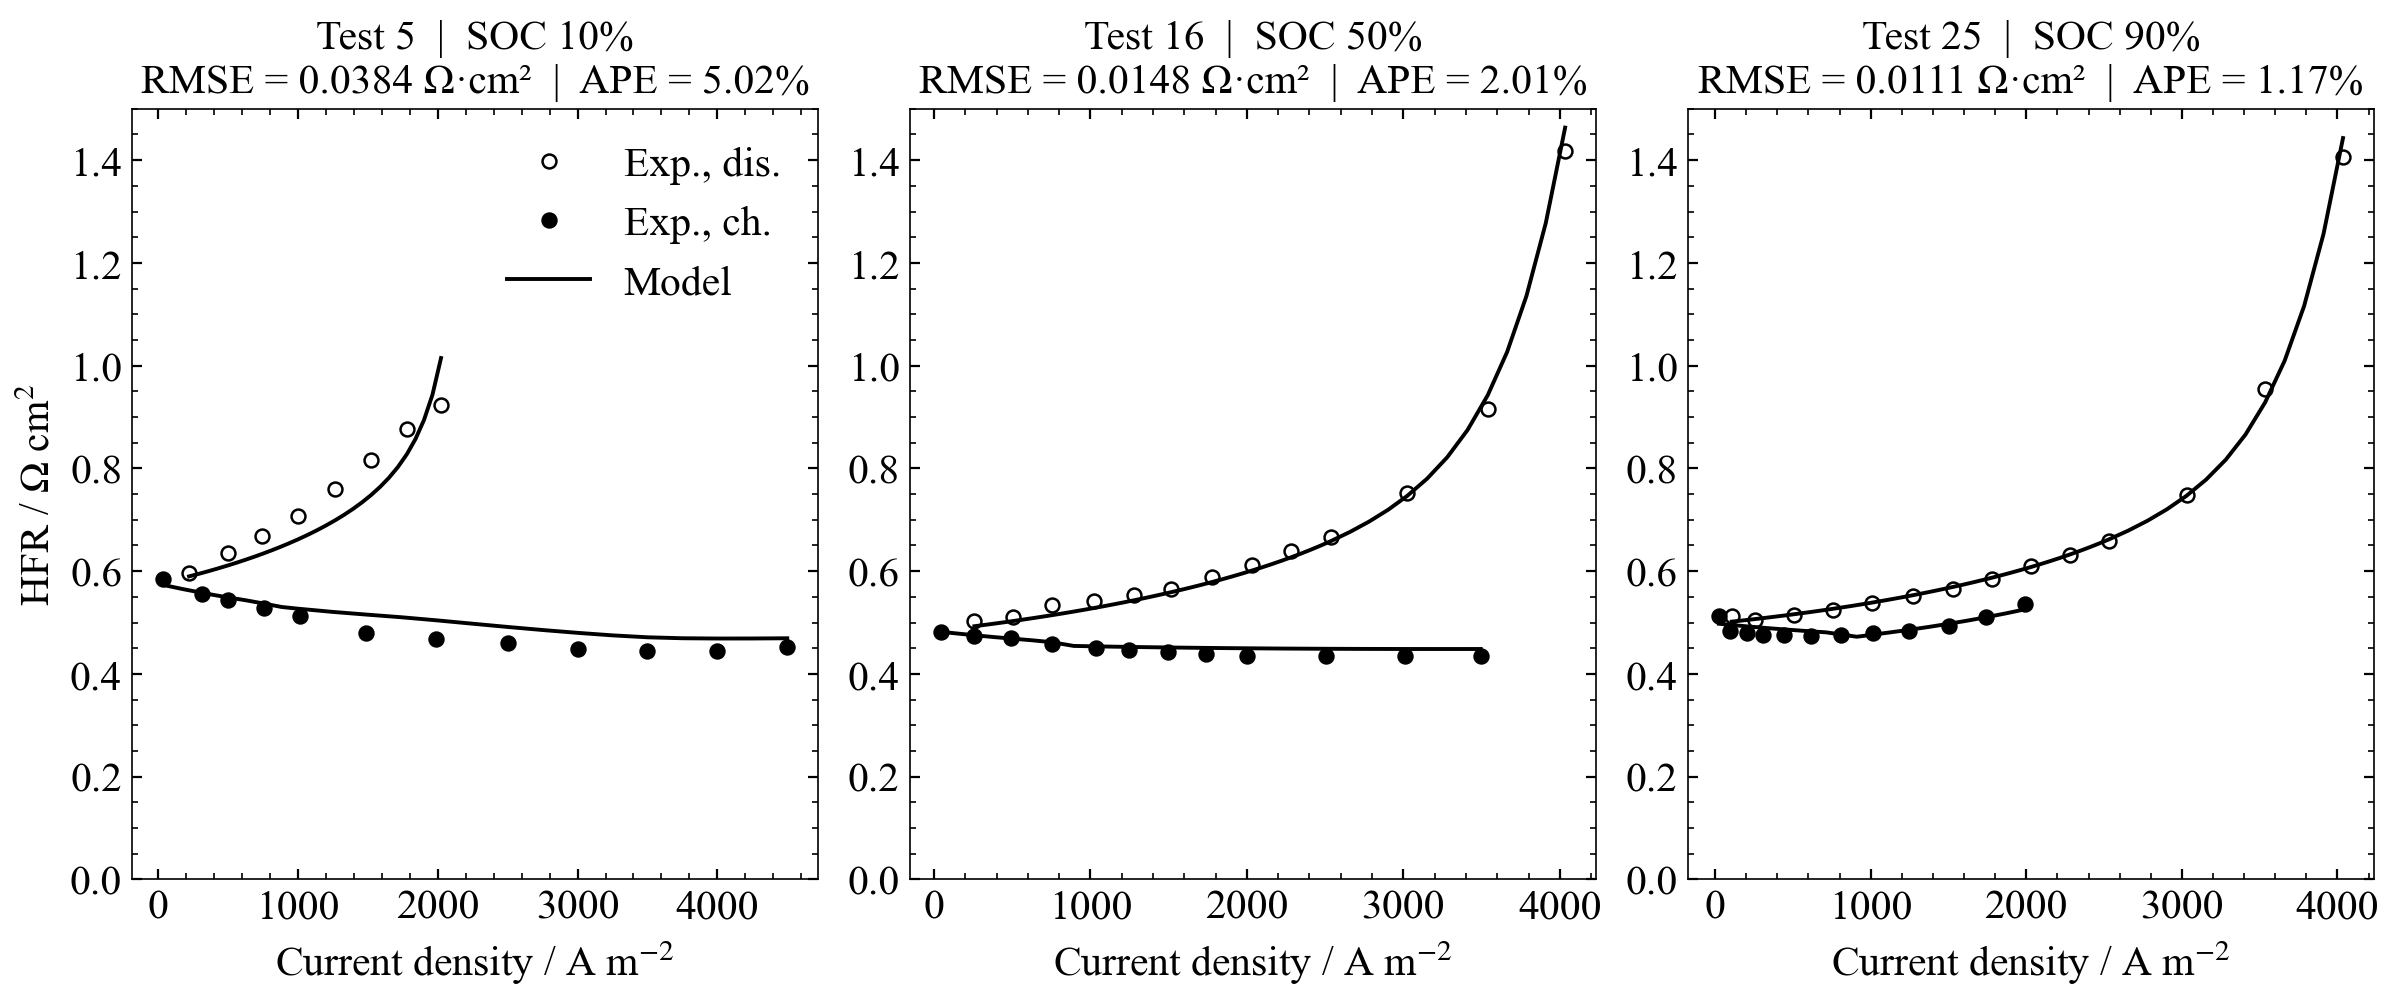

Saved -> <repo>\figures\HFR_global.pdf


In [5]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 15,
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'axes.linewidth': 0.6,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'lines.linewidth': 1.2,
    'savefig.dpi': 600,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Increase resolution by enlarging the canvas and saving at higher DPI.
fig, axes = plt.subplots(1, 3, figsize=(12, 5), dpi=200, sharey=False)

for ax, t in zip(axes, TEST_NOS):
    cfg = test_configs[t]
    r   = sim_results[t]

    # Experimental
    ax.plot(cfg["j_discharge"], cfg["HFR_exp_dis"],
            'o', ms=5, mfc='none', mec='k', mew=0.9, label='Exp., dis.')
    ax.plot(cfg["j_charge"],    cfg["HFR_exp_ch"],
            'o', ms=5, mfc='k',    mec='k', mew=0.9, label='Exp., ch.')

    # Model
    ax.plot(r["j_model_ch"],  r["HFR_model_ch"],  '-', color='k', lw=1.4, label='Model')
    ax.plot(r["j_model_dis"], r["HFR_model_dis"], '-', color='k', lw=1.4)

    ax.set_ylim(0, 1.5)
    ax.set_xlabel(r'Current density / A m$^{-2}$')
    ax.set_title(
        f"Test {t}  |  SOC {cfg['soc']:.0%}\n"
        f"RMSE = {r['mse']**0.5:.4f} Ω·cm²  |  APE = {r['ape']:.2f}%"
    )
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())

axes[0].set_ylabel('HFR / $\\Omega$ cm$^2$')
axes[0].legend(frameon=False)

fig.tight_layout(pad=0.4)
out_path = ROOT / "figures" / "HFR_global.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, dpi=600, bbox_inches='tight')
plt.show()
print(f"Saved -> {out_path}")

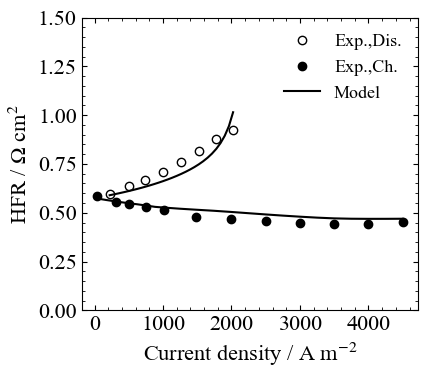

Saved -> <repo>\figures\HFR_test5.pdf


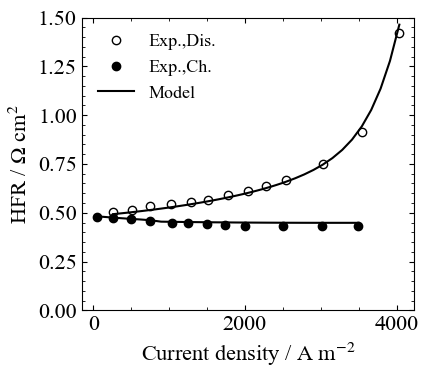

Saved -> <repo>\figures\HFR_test16.pdf


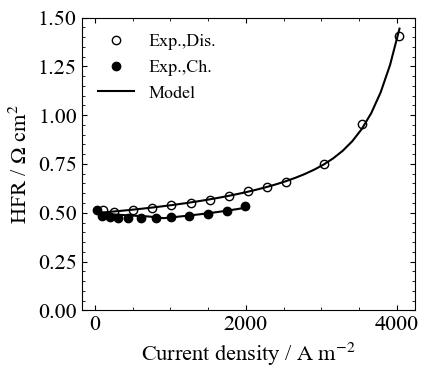

Saved -> <repo>\figures\HFR_test25.pdf

Per-test RMSE / APE:
  Test 5: RMSE = 0.0384 Ω·cm²  APE = 5.02%
  Test 16: RMSE = 0.0148 Ω·cm²  APE = 2.01%
  Test 25: RMSE = 0.0111 Ω·cm²  APE = 1.17%


In [6]:
plt.rcParams.update({
    'font.family':       'serif',
    'font.serif':        ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset':  'stix',
    'font.size':         14,
    'axes.labelsize':    16,
    'axes.titlesize':    16,
    'xtick.labelsize':   16,
    'ytick.labelsize':   16,
    'legend.fontsize':   13,
    'axes.linewidth':    0.8,
    'xtick.direction':   'in',
    'ytick.direction':   'in',
    'xtick.top':         True,
    'ytick.right':       True,
    'lines.linewidth':   1.5,
    'savefig.dpi':       600,
    'pdf.fonttype':      42,
    'ps.fonttype':       42,
})

for t in TEST_NOS:
    cfg = test_configs[t]
    r   = sim_results[t]

    fig, ax = plt.subplots(figsize=(4.5, 4))

    # Experimental: open circles (discharge), filled circles (charge)
    ax.plot(cfg["j_discharge"], cfg["HFR_exp_dis"],
            'o', ms=6, mfc='none', mec='k', mew=1.0, label='Exp.,Dis.')
    ax.plot(cfg["j_charge"],    cfg["HFR_exp_ch"],
            'o', ms=6, mfc='k',    mec='k', mew=1.0, label='Exp.,Ch.')

    # Model
    ax.plot(r["j_model_ch"],  r["HFR_model_ch"],  '-', color='k', lw=1.5, label='Model')
    ax.plot(r["j_model_dis"], r["HFR_model_dis"], '-', color='k', lw=1.5)

    ax.set_ylim(0, 1.5)
    ax.set_xlabel(r'Current density / A m$^{-2}$')
    ax.set_ylabel('HFR / $\\Omega$ cm$^2$')
    ax.legend(frameon=False)
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator())
    ax.tick_params(which='both', direction='in', top=True, right=True)

    plt.tight_layout()
    out_path = ROOT / f"figures/HFR_test{t}.pdf"
    out_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_path, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {out_path}")

# -- per-test MSE/APE summary --------------------------------------------
print("\nPer-test RMSE / APE:")
for t in TEST_NOS:
    r = sim_results[t]
    print(f"  Test {t}: RMSE = {r['mse']**0.5:.4f} Ω·cm²  APE = {r['ape']:.2f}%")